In [93]:
import pandas as pd
from datetime import datetime 
from pandas import DataFrame
import numpy as np
from matplotlib import pyplot as plt

In [94]:
columnasDates = ['year', 'month', 'day', 'hour']
df = pd.read_csv('raw.csv') 
df['dates'] = pd.to_datetime(df[columnasDates])
df.drop(columns=columnasDates, inplace=True)
df.set_index('dates',inplace=True)

df.drop(columns=['No'], inplace=True)
df.columns = ['pollution', 'dew', 'temp', 'press', 'wnd_dir', 'wnd_spd', 'snow', 'rain']
df['pollution'] = df['pollution'].fillna(0)
#empieza en la fila 24 (recuerda que empieza contando en 0, practicamente empieza en la fila numero 25
df = df[24:]
df.head()

,pollution,dew,temp,press,wnd_dir,wnd_spd,snow,rain
dates,,,,,,,,
2010-01-02 00:00:00,129.0,-16,-4.0,1020.0,SE,1.79,0,0
2010-01-02 01:00:00,148.0,-15,-4.0,1020.0,SE,2.68,0,0
2010-01-02 02:00:00,159.0,-11,-5.0,1021.0,SE,3.57,0,0
2010-01-02 03:00:00,181.0,-7,-5.0,1022.0,SE,5.36,1,0
2010-01-02 04:00:00,138.0,-7,-5.0,1022.0,SE,6.25,2,0


In [95]:
print(df.shape)
print(df.shape[0]/24)#cantidad de dias
print((df.shape[0]/24)/365)#cantidad de anios
print(365*24) #registros por anio

(43800, 8)
1825.0
5.0
8760


### Analisis Exploratorio

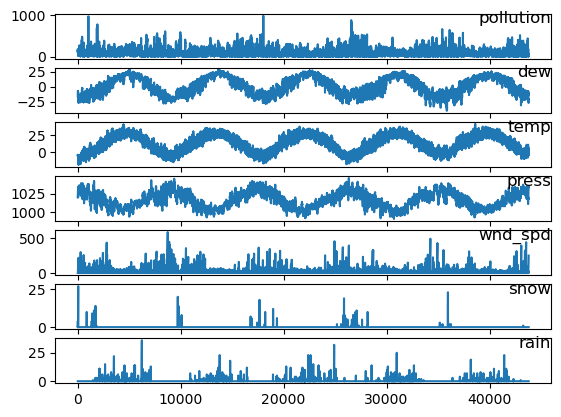

In [96]:
from matplotlib import pyplot as plt
values = df.values
groups = [0, 1, 2, 3, 5, 6, 7]
i = 1

for group in groups:
    plt.subplot(len(groups), 1, i)
    plt.plot(values[:, group])
    plt.title(f'{df.columns[group]}', y=0.6,loc='right')
    i+=1

plt.show()

In [97]:
# serie de numpy
#adelante: cuanto se necesita
def datos_a_supervisado(datos, atras=1, adelante=1, dropnan=True):
    n_vars = 1 if type(datos) is list else datos.shape[1]
    df = DataFrame(datos)
    cols, names = [], []
    for i in range (atras, 0,-1):
        cols.append(df.shift(i))
        names += [f'var{j+1}(t-{i})'for j in range(n_vars)]
    for i in range (0,adelante):
        cols.append(df.shift(-i))
        if (i == 0):
            names += [f'var{j+1}(t)' for j in range(n_vars)]
        else:
            names += [f'var{j+1}(t{i})' for j in range(n_vars)]
    agg = pd.concat(cols, axis=1) #Esto lo agrega en la derecha, no abajo, ojito
    agg.columns = names
    #print(agg)
    if dropnan:
        agg.dropna(inplace=True)
    return agg
        

In [98]:
#TEST
matriz = np.array([
    [1, 10],   # Fila 0
    [2, 20],   # Fila 1
    [3, 30],
    [4, 40]
])

datos_a_supervisado(matriz,2,1)

,var1(t-2),var2(t-2),var1(t-1),var2(t-1),var1(t),var2(t)
2,1.0,10.0,2.0,20.0,3,30
3,2.0,20.0,3.0,30.0,4,40


In [99]:
df.head()

,pollution,dew,temp,press,wnd_dir,wnd_spd,snow,rain
dates,,,,,,,,
2010-01-02 00:00:00,129.0,-16,-4.0,1020.0,SE,1.79,0,0
2010-01-02 01:00:00,148.0,-15,-4.0,1020.0,SE,2.68,0,0
2010-01-02 02:00:00,159.0,-11,-5.0,1021.0,SE,3.57,0,0
2010-01-02 03:00:00,181.0,-7,-5.0,1022.0,SE,5.36,1,0
2010-01-02 04:00:00,138.0,-7,-5.0,1022.0,SE,6.25,2,0


In [100]:
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import mean_squared_error

values = df.values
encoder = LabelEncoder()
values[:,4] = encoder.fit_transform(values[:,4])  #Selecciona la columna de direccion de 
#del viento para convertirlo en variables nominales 
values = values.astype('float32')
scaler = MinMaxScaler(feature_range =(0,1))
listaTran = scaler.fit_transform(values)
print(listaTran[:3,:])

[[0.12977867 0.35294122 0.24590163 0.5272732  0.6666667  0.00229001
  0.         0.        ]
 [0.14889336 0.36764708 0.24590163 0.5272732  0.6666667  0.00381099
  0.         0.        ]
 [0.15995975 0.4264706  0.22950819 0.545454   0.6666667  0.00533197
  0.         0.        ]]


In [101]:
print(listaTran.shape)
print(listaTran[:,-8]) #Esta es la fila de pollution, puedes ver que los valores
#coinciden con los de arriba, en todo caso, hazlo bien jejej 

(43800, 8)
[0.12977867 0.14889336 0.15995975 ... 0.01006036 0.00804829 0.01207243]


In [102]:
#Hasta aqui todo lo que se ha hecho a sido normalizar, finalmente se usa la funcion

'''Variables importantes que debes de usar en el futuro'''
horas_atras = 1
horas_adelante = 1 
n_variables = 8 

cambiado = datos_a_supervisado(listaTran, horas_atras, horas_adelante)
cambiado.head()

,var1(t-1),var2(t-1),var3(t-1),var4(t-1),var5(t-1),var6(t-1),var7(t-1),var8(t-1),var1(t),var2(t),var3(t),var4(t),var5(t),var6(t),var7(t),var8(t)
1,0.129779,0.352941,0.245902,0.527273,0.666667,0.002290,0.000000,0.0,0.148893,0.367647,0.245902,0.527273,0.666667,0.003811,0.000000,0.0
2,0.148893,0.367647,0.245902,0.527273,0.666667,0.003811,0.000000,0.0,0.159960,0.426471,0.229508,0.545454,0.666667,0.005332,0.000000,0.0
3,0.159960,0.426471,0.229508,0.545454,0.666667,0.005332,0.000000,0.0,0.182093,0.485294,0.229508,0.563637,0.666667,0.008391,0.037037,0.0
4,0.182093,0.485294,0.229508,0.563637,0.666667,0.008391,0.037037,0.0,0.138833,0.485294,0.229508,0.563637,0.666667,0.009912,0.074074,0.0
5,0.138833,0.485294,0.229508,0.563637,0.666667,0.009912,0.074074,0.0,0.109658,0.485294,0.213115,0.563637,0.666667,0.011433,0.111111,0.0


In [103]:
values=cambiado.values
values[:,-8] # Columna var1(t): contaminación de la hora actual, la variable a predecir.
              # Cada fila tiene las 8 variables de la hora anterior (t-1) y esta columna (t)

array([0.14889336, 0.15995975, 0.18209255, ..., 0.01006036, 0.00804829,
       0.01207243], dtype=float32)

In [104]:
#Solo funciona para una hora adelante
cuantos = [i for i in range(horas_atras*8+1, (horas_atras+horas_adelante)*8 )]
print(cuantos)
    
cambiado.drop(cambiado.columns[cuantos], axis=1,inplace=True)


[9, 10, 11, 12, 13, 14, 15]


In [105]:
cambiado.head()

,var1(t-1),var2(t-1),var3(t-1),var4(t-1),var5(t-1),var6(t-1),var7(t-1),var8(t-1),var1(t)
1,0.129779,0.352941,0.245902,0.527273,0.666667,0.002290,0.000000,0.0,0.148893
2,0.148893,0.367647,0.245902,0.527273,0.666667,0.003811,0.000000,0.0,0.159960
3,0.159960,0.426471,0.229508,0.545454,0.666667,0.005332,0.000000,0.0,0.182093
4,0.182093,0.485294,0.229508,0.563637,0.666667,0.008391,0.037037,0.0,0.138833
5,0.138833,0.485294,0.229508,0.563637,0.666667,0.009912,0.074074,0.0,0.109658


In [106]:
#Ignorar todo esto, solo es un mini formulario
'''
1D a 2D: 
y = train[:, -1]
# Opción 1: añadir una dimensión como columna
y_2d = y.reshape(-1, 1)
# Opción 2: usar newaxis
y_2d = y[:, np.newaxis]
2D a 1D:
y = train[:, -1:]
# Opción 1: seleccionar la primera (y única) columna
y_1d = y[:, 0]
# Opción 2: eliminar dimensiones de tamaño 1
y_1d = y.squeeze()
'''

'\n1D a 2D: \ny = train[:, -1]\n# Opción 1: añadir una dimensión como columna\ny_2d = y.reshape(-1, 1)\n# Opción 2: usar newaxis\ny_2d = y[:, np.newaxis]\n2D a 1D:\ny = train[:, -1:]\n# Opción 1: seleccionar la primera (y única) columna\ny_1d = y[:, 0]\n# Opción 2: eliminar dimensiones de tamaño 1\ny_1d = y.squeeze()\n'

In [107]:
values = cambiado.values
datos_para_entrenar = 365*24 #Cantidad de datos que se usan 

train = values[:datos_para_entrenar,:] #Se seleccionaron hasta la cantidad deseada de entrenamiento
#Recuerda [(incluye):(excluye) ,(incluye):(excluye)]
test = values[datos_para_entrenar:,:] #Se selecciona desde la cantidad hasta el final (filas)

train_X, train_y = train[: , :-1], train[: , -1]
test_X, test_y = test[: , :-1], test[: , -1]
print(train_X.shape, train_y.shape, test_X.shape, test_y.shape)

(8760, 8) (8760,) (35039, 8) (35039,)


In [108]:
#Ahora para realizar LSTM se necesita un array 3D
#Por la naturaleza de LSTM se necesita la siguiente estructura para predecir:

# (muestras, pasos de tiempo, variables)
# (samples,  timesteps,       features)
train_X = train_X.reshape((train_X.shape[0], 1, train_X.shape[1])) 
test_X = test_X.reshape((test_X.shape[0], 1, test_X.shape[1]))
# Así que pasa de (8760, 8) a (8760, 1, 8). 
#Cada hora, que era una fila de 8 números, 
#ahora es una mini-tabla de 1 fila × 8 columnas.
print(train_X.shape, train_y.shape, test_X.shape, test_y.shape)
'''No volver a tocar mas de una vez, JAMAS, NADA, 
SI LO CORRES DE NUEVO TRATA DE hacer un array 3D 
del que ya existe!!!''' 

(8760, 1, 8) (8760,) (35039, 1, 8) (35039,)


'No volver a tocar mas de una vez, JAMAS, NADA, \nSI LO CORRES DE NUEVO TRATA DE hacer un array 3D \ndel que ya existe!!!'

In [109]:
from keras.models import Sequential
from keras.layers import Dense
from keras.layers import LSTM
#No he revisado nada desde aqui, pero entiendo lo basico, tengo que revisarlo mas y mas.
model = Sequential()
model.add(LSTM(50, input_shape=(train_X.shape[1], train_X.shape[2])))
model.add(Dense(1))
model.compile(loss='mae', optimizer='adam')

C:\Users\alexi\anaconda3\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/50
122/122 - 2s - 13ms/step - loss: 0.0601 - val_loss: 0.0537
Epoch 2/50
122/122 - 1s - 4ms/step - loss: 0.0408 - val_loss: 0.0522
Epoch 3/50
122/122 - 0s - 4ms/step - loss: 0.0222 - val_loss: 0.0417
Epoch 4/50
122/122 - 0s - 4ms/step - loss: 0.0163 - val_loss: 0.0291
Epoch 5/50
122/122 - 1s - 4ms/step - loss: 0.0152 - val_loss: 0.0188
Epoch 6/50
122/122 - 1s - 4ms/step - loss: 0.0149 - val_loss: 0.0164
Epoch 7/50
122/122 - 0s - 4ms/step - loss: 0.0148 - val_loss: 0.0157
Epoch 8/50
122/122 - 1s - 4ms/step - loss: 0.0148 - val_loss: 0.0154
Epoch 9/50
122/122 - 1s - 4ms/step - loss: 0.0148 - val_loss: 0.0153
Epoch 10/50
122/122 - 1s - 4ms/step - loss: 0.0146 - val_loss: 0.0144
Epoch 11/50
122/122 - 1s - 4ms/step - loss: 0.0146 - val_loss: 0.0143
Epoch 12/50
122/122 - 0s - 4ms/step - loss: 0.0146 - val_loss: 0.0142
Epoch 13/50
122/122 - 0s - 4ms/step - loss: 0.0146 - val_loss: 0.0139
Epoch 14/50
122/122 - 1s - 4ms/step - loss: 0.0146 - val_loss: 0.0141
Epoch 15/50
122/122 - 1s - 4

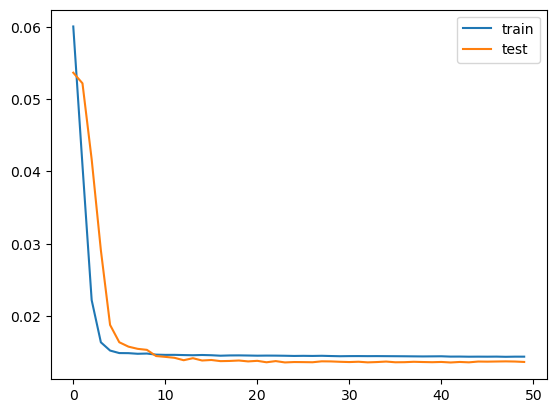

In [110]:
history = model.fit(train_X, train_y, epochs=50, batch_size=72, validation_data=(test_X, test_y), verbose=2, shuffle=False)
# plot history
plt.plot(history.history['loss'], label='train')
plt.plot(history.history['val_loss'], label='test')
plt.legend()
plt.show()
'''En cuanto a esto tambien tener cuidado
Solo correr una vez, si algo de plt se rompe o algo mas abajo se rompe
correr todo desde el principio de nuevo, o si no entrenaras al mismo
modelo mas de una vez!!!''' 